# **Cybersäkerhetsanalys av Webbläsarhistorik med hjälp av Isolation Forest**
**Detta skript analyserar webbläsarhistorik för att identifiera potentiella säkerhetsrisker med hjälp av maskininlärning.**

**Steg 1: Ladda upp och förbereda data**

In [20]:
# Importera nödvändiga bibliotek
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from google.colab import files

# Ladda upp din CSV-fil
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# Visa de första 5 raderna för att kontrollera data
print("Första 5 raderna av originaldata:")
display(df.head())

Saving web history (forever).csv to web history (forever) (2).csv
Första 5 raderna av originaldata:


,order,id,date,time,title,url,typedCount,visitCount,transition
0,0,2862,4/14/2025,12:45:17,month - Google Search,https://www.google.com/search?sca_esv=b51c10b8...,0,1,link
1,1,2861,4/14/2025,12:45:16,mounth - Google Search,https://www.google.com/search?q=mounth&oq=moun...,0,1,generated
2,2,2860,4/14/2025,12:28:37,Quick Chrome History Export - Google Search,https://www.google.com/search?q=Quick+Chrome+H...,0,1,generated
3,3,2859,4/14/2025,12:28:33,Регистрация - Tilda,https://tilda.cc/registration/,0,1,link
4,4,2858,4/14/2025,12:12:37,3d Objects Generator,https://deepai.org/machine-learning-model/3d-o...,0,1,link


**Steg 2: Datarensning och funktionsextrahering**

In [21]:
# Skapa tidstämpel från datum och tid
df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])

# Extrahera viktiga funktioner
df['hour'] = df['datetime'].dt.hour  # Timme på dygnet
df['day_of_week'] = df['datetime'].dt.dayofweek  # Veckodag (0=måndag)
df['domain'] = df['url'].str.extract(r'https?://([^/]+)')  # Extrahera domännamn

# Skapa säkerhetsrelaterade funktioner
df['is_google_search'] = df['url'].str.contains('google.com/search', regex=False).astype(int)
df['is_http'] = df['url'].str.startswith('http://').astype(int)  # HTTP är mindre säkert än HTTPS
df['url_length'] = df['url'].str.len()  # Långa URL:er kan vara misstänkta

# Kodom kategoriska variabler
le = LabelEncoder()
df['domain_encoded'] = le.fit_transform(df['domain'].fillna('unknown'))

# Beräkna besöksfrekvens per domän
df['visit_freq'] = df.groupby('domain')['domain'].transform('count')

# Visa de nya funktionerna
print("\nData med extraherade funktioner:")
display(df[['datetime', 'domain', 'hour', 'day_of_week', 'is_http', 'visit_freq']].head())



Data med extraherade funktioner:


,datetime,domain,hour,day_of_week,is_http,visit_freq
0,2025-04-14 12:45:17,www.google.com,12,0,0,76.0
1,2025-04-14 12:45:16,www.google.com,12,0,0,76.0
2,2025-04-14 12:28:37,www.google.com,12,0,0,76.0
3,2025-04-14 12:28:33,tilda.cc,12,0,0,1.0
4,2025-04-14 12:12:37,deepai.org,12,0,0,35.0


**Steg 3: Träna avvikelsedetektionsmodell**

In [22]:
# Välj relevanta funktioner för modellen
features = ['hour', 'day_of_week', 'is_http', 'url_length', 'visit_freq', 'domain_encoded']
X = df[features].fillna(0)

# Skapa och träna Isolation Forest-modell
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,  # Förväntad andel avvikelser (5%)
    random_state=42
)
model.fit(X)

# Förutsäg avvikelser (-1 = avvikelse, 1 = normal)
df['anomaly_score'] = model.decision_function(X)
df['is_anomaly'] = model.predict(X)

**Steg 4.1: Analysera resultat och identifiera risker**

In [23]:
# Visa de mest avvikande posterna
anomalies = df[df['is_anomaly'] == -1].sort_values('anomaly_score')
print(f"\nHittade {len(anomalies)} potentiella säkerhetsrisker:")

# Skapa en klassificering av risknivå
def classify_risk(row):
    if row['is_http'] and not row['is_google_search']:
        return "Hög risk (HTTP + okänd domän)"
    elif row['visit_freq'] == 1 and not row['is_google_search']:
        return "Medel risk (Första besöket)"
    else:
        return "Låg risk (Potentiell avvikelse)"

anomalies['risk_level'] = anomalies.apply(classify_risk, axis=1)

# Visa de viktigaste riskerna
display(anomalies[['datetime', 'domain', 'url', 'risk_level', 'anomaly_score']].sort_values('anomaly_score'))


Hittade 44 potentiella säkerhetsrisker:


,datetime,domain,url,risk_level,anomaly_score
546,2025-02-05 18:51:10,github.com,https://github.com/login?return_to=https%3A%2F...,Medel risk (Första besöket),-0.070795
353,2025-02-08 14:49:17,www.capcut.com,https://www.capcut.com/lvpc_web/login_status#s...,Medel risk (Första besöket),-0.067271
50,2025-04-12 20:45:59,accounts.google.com,https://accounts.google.com/signin/oauth/conse...,Låg risk (Potentiell avvikelse),-0.063240
51,2025-04-12 20:45:58,accounts.google.com,https://accounts.google.com/signin/oauth/id?au...,Låg risk (Potentiell avvikelse),-0.061478
339,2025-02-09 17:32:55,accounts.google.com,https://accounts.google.com/signin/oauth/id?au...,Låg risk (Potentiell avvikelse),-0.061028
381,2025-02-08 14:28:49,app.runwayml.com,https://app.runwayml.com/google-sign-in-redire...,Låg risk (Potentiell avvikelse),-0.034574
68,2025-04-12 09:30:03,accounts.google.com,https://accounts.google.com/signin/oauth/id?au...,Låg risk (Potentiell avvikelse),-0.033755
87,2025-04-04 16:23:28,accounts.google.com,https://accounts.google.com/signin/oauth/conse...,Låg risk (Potentiell avvikelse),-0.033676
88,2025-04-04 16:23:26,accounts.google.com,https://accounts.google.com/signin/oauth/id?au...,Låg risk (Potentiell avvikelse),-0.029220
619,2025-02-04 20:38:26,accounts.google.com,https://accounts.google.com/signin/oauth/id?au...,Låg risk (Potentiell avvikelse),-0.028954


**Steg 4.2: Analysera resultat och identifiera risker**

In [27]:
# Filtrera avvikelser
anomalies = df[df['is_anomaly'] == -1].copy()

# Skapa en klassificering av risknivå
def classify_risk(row):
    if row['is_http'] and not row['is_google_search']:
        return "Hög risk (HTTP + okänd domän)"
    elif row['visit_freq'] == 1 and not row['is_google_search']:
        return "Medel risk (Första besöket)"
    else:
        return "Låg risk (Potentiell avvikelse)"

# Tillämpa klassificeringen
anomalies['risk_level'] = anomalies.apply(classify_risk, axis=1)

# Sortera efter avvikelsescore
anomalies = anomalies.sort_values('anomaly_score')

# Gruppera efter risknivå
risk_groups = anomalies.groupby('risk_level')

# Starta rapporten
print(f"🔍 ANALYSRESULTAT (Hittade {len(anomalies)} avvikande besök)")
print("=" * 50)

# Definiera ordningen för risknivåer
risk_order = [
    "Hög risk (HTTP + okänd domän)",
    "Medel risk (Första besöket)",
    "Låg risk (Potentiell avvikelse)"
]

# Iterera över risknivåerna i definierad ordning
for risk in risk_order:
    if risk in risk_groups.groups:
        group = risk_groups.get_group(risk)
        print(f"\n⭐ {risk.upper()} ⭐ ({len(group)} besök)")
        print("-" * 40)
        for _, row in group.iterrows():
            print(f"\n📅 {row['datetime']}")
            print(f"🌐 Domän: {row['domain']}")
            print(f"🔗 URL: {row['url']}")
            print(f"📊 Avvikelsescore: {row['anomaly_score']:.4f}")
            if risk == "Medel risk (Första besöket)":
                print("ℹ️ INFO: Första besöket på denna webbplats")

# Avsluta rapporten
print("\n" + "=" * 50)
print("SLUT PÅ RAPPORT")


🔍 ANALYSRESULTAT (Hittade 44 avvikande besök)

⭐ MEDEL RISK (FÖRSTA BESÖKET) ⭐ (3 besök)
----------------------------------------

📅 2025-02-05 18:51:10
🌐 Domän: github.com
🔗 URL: https://github.com/login?return_to=https%3A%2F%2Fgithub.com%2Fn8n-io%2Fn8n%2Fissues%2Fnew%3Flabels%3Dbug-report%26body%3D%250A%253C%2521--%2BPlease%2Bfollow%2Bthe%2Btemplate%2Bbelow.%2BSkip%2Bthe%2Bquestions%2Bthat%2Bare%2Bnot%2Brelevant%2Bto%2Byou.%2B--%253E%250A%250A%2523%2523%2BDescribe%2Bthe%2Bproblem%252Ferror%252Fquestion%250A%250A%250A%2523%2523%2BWhat%2Bis%2Bthe%2Berror%2Bmessage%2B%2528if%2Bany%2529%253F%250A%250A%250A%2523%2523%2BPlease%2Bshare%2Byour%2Bworkflow%252Fscreenshots%252Frecording%250A%250A%2560%2560%2560%250A%2528Select%2Bthe%2Bnodes%2Bon%2Byour%2Bcanvas%2Band%2Buse%2Bthe%2Bkeyboard%2Bshortcuts%2BCMD%252BC%252FCTRL%252BC%2Band%2BCMD%252BV%252FCTRL%252BV%2Bto%2Bcopy%2Band%2Bpaste%2Bthe%2Bworkflow.%2529%250A%25E2%259A%25A0%25EF%25B8%258F%2BWARNING%2B%25E2%259A%25A0%25EF%25B8%258F%2BIf%2Byo

**Steg 5: Visualisera resultat**

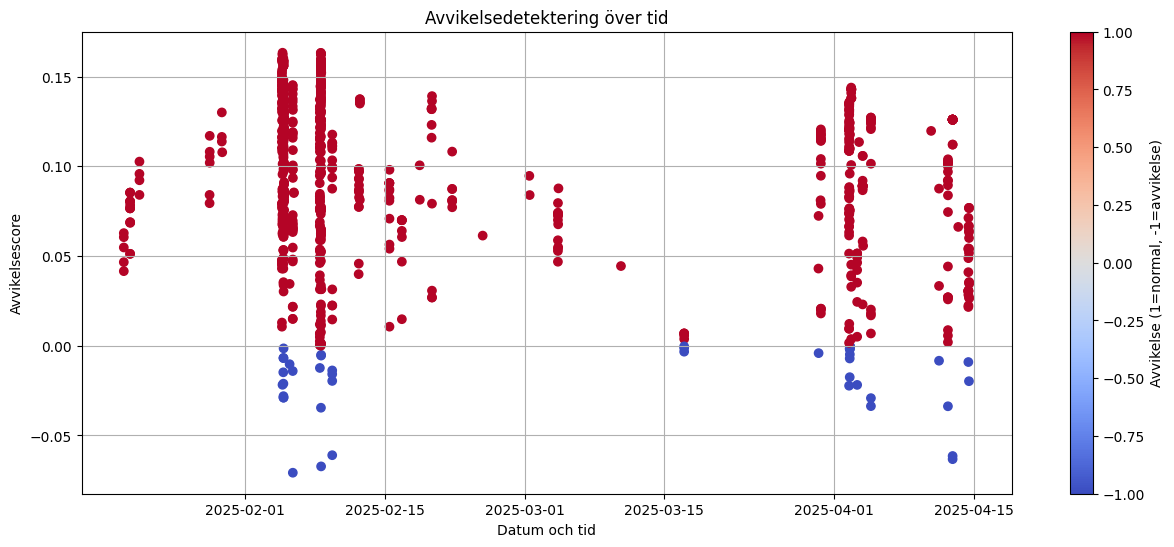

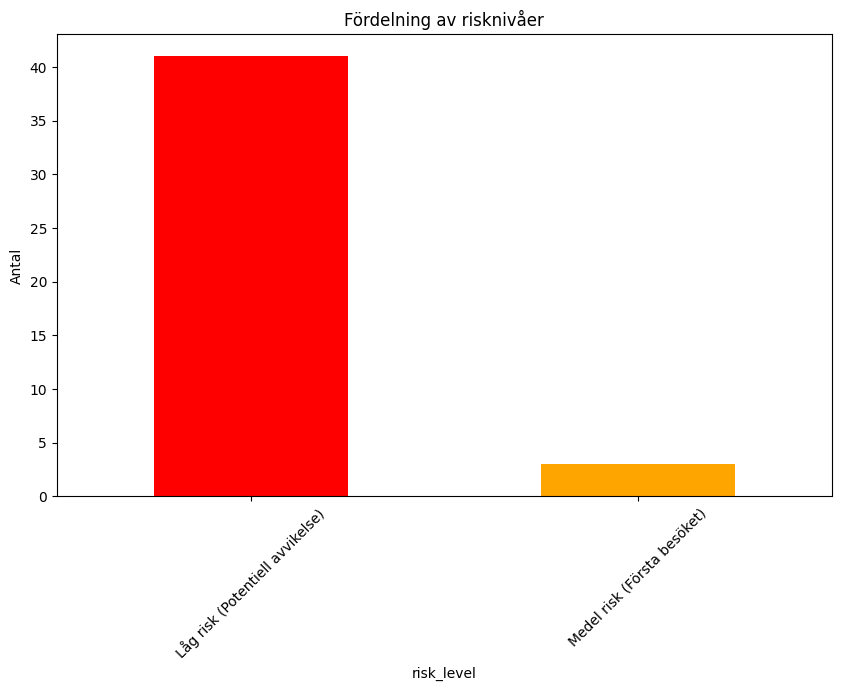

In [24]:
# Plotta avvikelsescore över tid
plt.figure(figsize=(15, 6))
plt.scatter(df['datetime'], df['anomaly_score'], c=df['is_anomaly'], cmap='coolwarm')
plt.title('Avvikelsedetektering över tid')
plt.xlabel('Datum och tid')
plt.ylabel('Avvikelsescore')
plt.colorbar(label='Avvikelse (1=normal, -1=avvikelse)')
plt.grid(True)
plt.show()

# Visa riskfördelning
risk_counts = anomalies['risk_level'].value_counts()
plt.figure(figsize=(10, 6))
risk_counts.plot(kind='bar', color=['red', 'orange', 'yellow'])
plt.title('Fördelning av risknivåer')
plt.ylabel('Antal')
plt.xticks(rotation=45)
plt.show()

**Resultat tolkning:**

Totalt **44 potentiella säkerhetsrisker** har identifierats i din **webbhistorik**.

Dessa risker är klassificerade som antingen "**Låg risk** (Potentiell avvikelse)" eller "**Medel risk** (Första besöket)".​

Många av dessa risker är kopplade till **inloggningssidor**, särskilt från domäner som **accounts.google.com, login.live.com, slack.com och github.com**.

# **Förbättrad Cybersäkerhetsanalys av Webbläsarhistorik med hjälp av Isolation Forest, Random Forest, DBSCAN**
1. **Fler avancerade modeller**: Använder nu ***Isolation Forest, DBSCAN*** och ***Random Forest*** för bättre noggrannhet
2. **Bättre förklaringar**: Ger detaljerade förklaringar till varför varje besök flaggas som risk.
3. **Fler funktioner**: Extraherar fler relevanta säkerhetsrelaterade funktioner
4. **Förbättrad visualisering**: Mer informativa grafer och diagram
5. **Automatisk rapportgenerering**: Skapar en strukturerad rapport med nyckelstatistik
6. **Riskbedömning**: Mer nyanserad riskklassificering med kombinerade modellresultat

**Steg 1: Ladda upp och förbereda data**

In [40]:
!pip install tldextract
# Importera nödvändiga bibliotek
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import re
from datetime import datetime
import ipaddress
import tldextract

# Ladda upp CSV-fil
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# Visa dataöversikt
print("Dataöversikt:")
display(df.head())
print(f"\nTotalt antal besök: {len(df)}")

Saving web history (forever).csv to web history (forever) (5).csv
Dataöversikt:


,order,id,date,time,title,url,typedCount,visitCount,transition
0,0,2862,4/14/2025,12:45:17,month - Google Search,https://www.google.com/search?sca_esv=b51c10b8...,0,1,link
1,1,2861,4/14/2025,12:45:16,mounth - Google Search,https://www.google.com/search?q=mounth&oq=moun...,0,1,generated
2,2,2860,4/14/2025,12:28:37,Quick Chrome History Export - Google Search,https://www.google.com/search?q=Quick+Chrome+H...,0,1,generated
3,3,2859,4/14/2025,12:28:33,Регистрация - Tilda,https://tilda.cc/registration/,0,1,link
4,4,2858,4/14/2025,12:12:37,3d Objects Generator,https://deepai.org/machine-learning-model/3d-o...,0,1,link



Totalt antal besök: 881


**Steg 2: Avancerad datarensning och funktionsextrahering**

In [41]:
# Förbättrad funktionsextrahering
def extract_features(df):
    # Tid-relaterade funktioner
    df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])
    df['hour'] = df['datetime'].dt.hour
    df['day_of_week'] = df['datetime'].dt.dayofweek
    df['is_weekend'] = df['day_of_week'].isin([5,6]).astype(int)

    # URL-relaterade funktioner
    df['domain'] = df['url'].apply(lambda x: tldextract.extract(x).registered_domain)
    df['is_http'] = df['url'].str.startswith('http://').astype(int)
    df['url_length'] = df['url'].str.len()
    df['num_params'] = df['url'].str.count(r'\?|&')
    df['has_ip'] = df['url'].apply(lambda x: bool(re.search(r'\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}', x))).astype(int)

    # Innehållsrelaterade funktioner
    df['is_login'] = df['url'].str.contains(r'login|signin|auth|authentication', regex=True).astype(int)
    df['is_oauth'] = df['url'].str.contains(r'oauth|auth2', regex=True).astype(int)
    df['is_search'] = df['url'].str.contains(r'search\?|query=', regex=True).astype(int)

    # Besöksfrekvens
    df['visit_freq'] = df.groupby('domain')['domain'].transform('count')
    df['user_freq'] = df.groupby('url')['url'].transform('count')

    return df

df = extract_features(df)

# Visa de nya funktionerna
print("\nExempel på extraherade funktioner:")
display(df[['datetime', 'domain', 'hour', 'is_http', 'is_login', 'visit_freq']].head())


Exempel på extraherade funktioner:


,datetime,domain,hour,is_http,is_login,visit_freq
0,2025-04-14 12:45:17,google.com,12,0,0,289
1,2025-04-14 12:45:16,google.com,12,0,0,289
2,2025-04-14 12:28:37,google.com,12,0,0,289
3,2025-04-14 12:28:33,tilda.cc,12,0,0,1
4,2025-04-14 12:12:37,deepai.org,12,0,0,36


**Steg 3: Träna flera avvikelsedetektionsmodeller**

In [42]:
# Förbered data
features = ['hour', 'day_of_week', 'is_weekend', 'is_http', 'url_length',
            'num_params', 'has_ip', 'is_login', 'is_oauth', 'is_search',
            'visit_freq', 'user_freq']

# Kodom domäner
le = LabelEncoder()
df['domain_encoded'] = le.fit_transform(df['domain'].fillna('unknown'))

# Skala numeriska funktioner
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features + ['domain_encoded']])

# Modell 1: Isolation Forest
iso_forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
df['iso_anomaly'] = iso_forest.fit_predict(X_scaled)
df['iso_score'] = iso_forest.decision_function(X_scaled)

# Modell 2: DBSCAN för klustring av avvikande mönster
dbscan = DBSCAN(eps=0.5, min_samples=5)
df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

# Modell 3: Random Forest för riskklassificering
# Skapa målet baserat på kombination av modellerna
df['high_risk'] = ((df['iso_anomaly'] == -1) &
                   (df['dbscan_cluster'] == -1) &
                   (df['is_http'] == 1)).astype(int)

if df['high_risk'].sum() > 0:  # Endast träna om vi har positiva exempel
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_scaled, df['high_risk'])
    df['rf_risk_score'] = rf.predict_proba(X_scaled)[:, 1]
else:
    df['rf_risk_score'] = 0

# Kombinera modellresultat
df['combined_risk'] = (0.4*df['iso_score'].rank(pct=True) +
                      0.3*(df['dbscan_cluster'] == -1).astype(int) +
                      0.3*df['rf_risk_score'])

**Steg 4: Förbättrad riskanalys och förklaringar**

In [43]:
def explain_risk(row):
    explanations = []

    # HTTP vs HTTPS
    if row['is_http']:
        explanations.append("Använder osäkert HTTP-protokoll")

    # OAuth/Login-sidor
    if row['is_oauth']:
        explanations.append("Involverar OAuth-autentisering")
    elif row['is_login']:
        explanations.append("Innehåller inloggningsformulär")

    # IP-adresser
    if row['has_ip']:
        explanations.append("Använder IP-adress direkt istället för domännamn")

    # Parameterantal
    if row['num_params'] > 5:
        explanations.append(f"Många URL-parametrar ({row['num_params']})")

    # Ovanliga besökstider
    if row['hour'] < 6 or row['hour'] > 22:
        explanations.append(f"Ovanlig besökstid ({row['hour']}:00)")

    # Låg besöksfrekvens
    if row['visit_freq'] == 1:
        explanations.append("Första besöket på denna domän")

    # Kombinera förklaringar
    if not explanations:
        return "Inga tydliga riskindikatorer"

    risk_level = "Medel risk"
    if row['is_http'] and row['is_login']:
        risk_level = "Hög risk"
    elif row['has_ip'] or row['num_params'] > 5:
        risk_level = "Hög risk"

    return f"{risk_level}: " + ", ".join(explanations)

df['risk_explanation'] = df.apply(explain_risk, axis=1)

# Visa de viktigaste riskerna
high_risk = df[df['combined_risk'] > df['combined_risk'].quantile(0.95)].sort_values('combined_risk', ascending=False)
print(f"\nHittade {len(high_risk)} potentiella säkerhetsrisker:")

# Gruppera risker efter typ
risk_counts = high_risk['risk_explanation'].value_counts()
print("\nRiskfördeling:")
display(risk_counts)


Hittade 44 potentiella säkerhetsrisker:

Riskfördeling:


,count
risk_explanation,
Inga tydliga riskindikatorer,41
Medel risk: Första besöket på denna domän,3


**Steg 5.1: Avancerad visualisering**
**Riskfördelning per domän**

<ipython-input-44-80bfb0e18476>:13: UserWarning: Glyph 127760 (\N{GLOBE WITH MERIDIANS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127760 (\N{GLOBE WITH MERIDIANS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


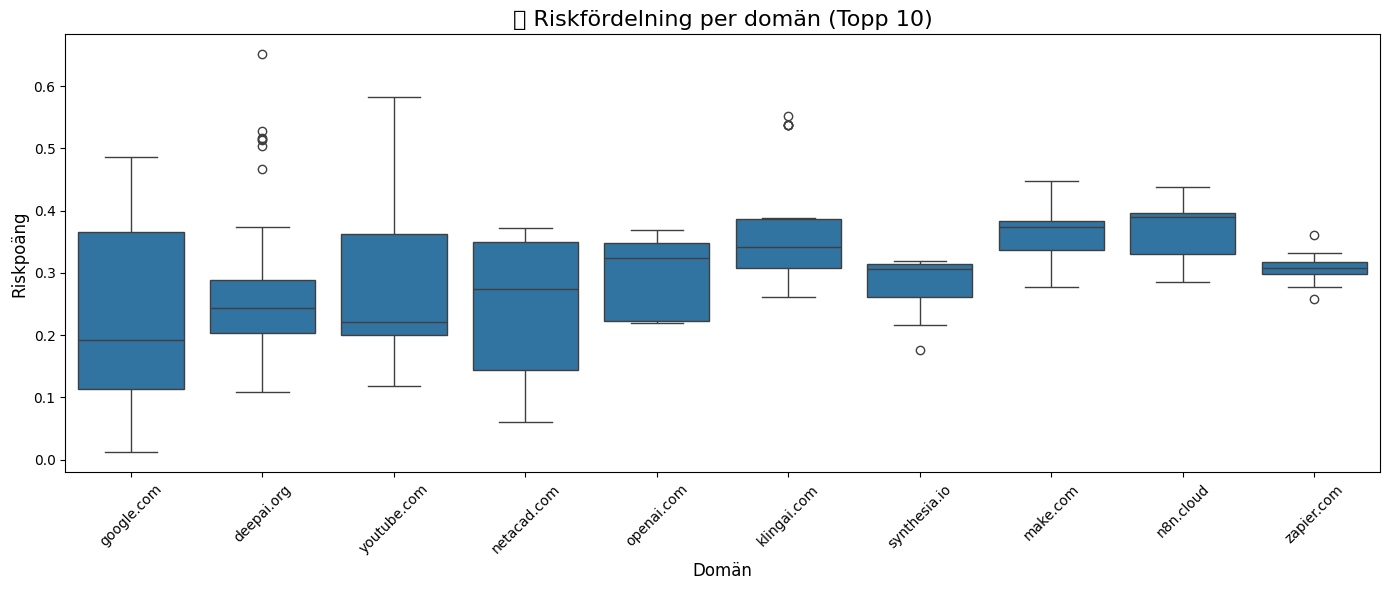

In [44]:
# Visar hur riskpoängen varierar för de 10 mest besökta domänerna.
top_domains = df['domain'].value_counts().nlargest(10).index
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df[df['domain'].isin(top_domains)],
    x='domain',
    y='combined_risk'
)
plt.title('🌐 Riskfördelning per domän (Topp 10)', fontsize=16)
plt.xlabel('Domän', fontsize=12)
plt.ylabel('Riskpoäng', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Domän	Tolkning**

Grafen visualiserar riskpoängens fördelning för de ***10 mest besökta domänerna***. Varje "box" visar hur spridd riskbedömningen är för den specifika domänen.

1. ***google.com***	Stor spridning i riskpoäng, vissa extremt låga (nära 0). Vissa höga outliers. Detta tyder på både säkra och avvikande besök till Google.

2. ***deepai.org***	Låg medianrisk, men flera outliers. Kan antyda att sajten oftast är trygg men har haft vissa avvikande sessioner.

3. ***youtube.com***	Riskerna varierar ganska mycket. En bred box visar hög variation i beteendet på sajten.

4. ***openai.com***	Ganska stabila riskpoäng, men en något högre median. Kan tyda på att OpenAI:s domän uppfattas som tekniskt men inte nödvändigtvis riskfylld.

5. ***kingai.com och n8n.cloud***	 Har relativt konsekventa och medelhöga riskpoäng, vilket kan bero på att de är mindre kända och saknar historik.

6. ***zapier.com***	 Har mycket låg spridning i riskpoäng – väldigt konsekvent. Låg risk.

**Vad kan man dra för slutsats?**

Om en domän har hög spridning i riskpoäng → kan vara normalt med varierande användningsmönster (t.ex. Google).

Smala boxar med hög median → kan tyda på att domänen ofta uppfattas som "misstänkt" (beroende på vad modellen lärt sig).

Många outliers → tecken på vissa väldigt ovanliga sessioner som bör granskas manuellt.

**Steg 5.2: Avancerad visualisering**
**Avvikelsescore över tid**

<ipython-input-46-2a64079e893b>:16: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


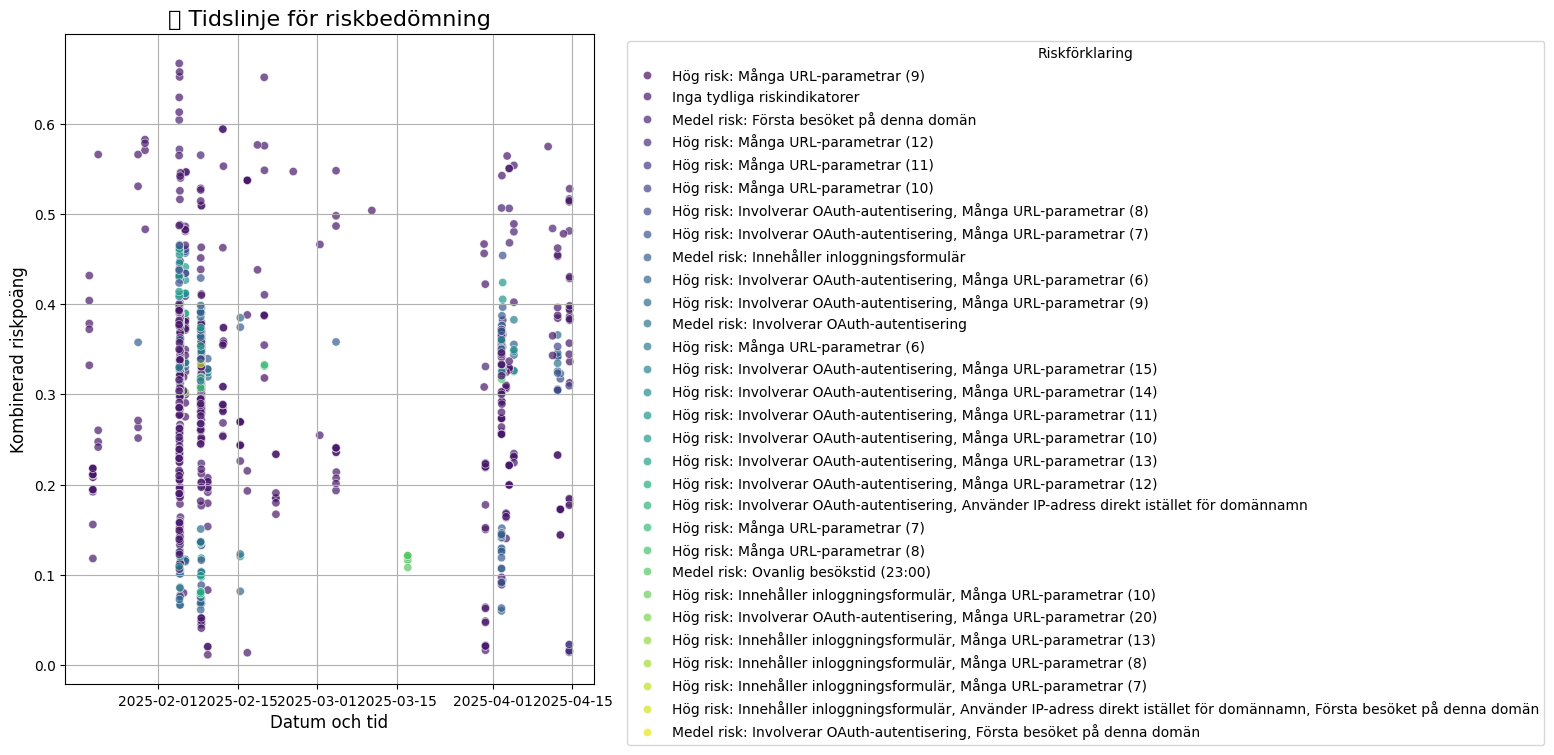

In [46]:
# Visualiserar kombinerad riskpoäng över tid för varje besök.
plt.figure(figsize=(16, 8))
sns.scatterplot(
    data=df,
    x='datetime',
    y='combined_risk',
    hue='risk_explanation',  # Visar förklaringar till varför något klassas som risk
    palette='viridis',
    alpha=0.7
)
plt.title('🕒 Tidslinje för riskbedömning', fontsize=16)
plt.xlabel('Datum och tid', fontsize=12)
plt.ylabel('Kombinerad riskpoäng', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Riskförklaring")
plt.grid(True)
plt.tight_layout()
plt.show()

Grafen är ett scatterplot (punktdiagram) som visar hur den kombinerade riskpoängen för varje ***webbplatsbesök varierar över tid***. Färgerna representerar olika riskförklaringar, alltså varför ett besök har fått en viss risknivå.

🧠 ***Hur tolkar man den?***

X-axeln = Tidslinje (från februari till april 2025)

Y-axeln = Kombinerad riskpoäng (från 0 till ~0.65)

Varje punkt = Ett besök

Färg på punkten = Vilken typ av riskfaktor som har identifierats (t.ex. många URL-parametrar, OAuth, IP-adress)

✨ ***Viktiga observationer***

📈 1. Hög risk är ofta kopplad till URL-parametrar och OAuth
Många punkter med förklaringar som:

”Hög risk: Många URL-parametrar (14)”

”Hög risk: Involverar OAuth-autentisering”

Dessa punkter ligger högt på Y-axeln, vilket indikerar ökad risk när dessa faktorer förekommer.

Flera punkter har både OAuth och många parametrar → kombinerade faktorer = högre poäng.

📅 ***2. Tidskluster***:

Många riskhändelser inträffade under februari
Tät klustring av punkter mellan 1–20 februari 2025.

Detta kan tyda på ett ovanligt mönster av användarbeteende eller en viss attackperiod, t.ex. testning eller phishingförsök.

🟢 ***3. Lågriskpunkter finns – men är färre***

Några få punkter har förklaringar som:

”Medel risk: Första besöket”

”Inga tydliga riskindikatorer”

Dessa är längre ner i grafen, vilket tyder på tryggare eller neutral trafik.

🧩 ***4. Flera kombinerade risker***

Vissa förklaringar innehåller flera faktorer samtidigt, t.ex.:

"Innehåller inloggningsformulär, Använder IP-adress direkt, Första besöket"

När flera sådana faktorer samlas → poängen skjuter i höjden.

📌 ***Slutsatser***

🔐 OAuth-autentisering och många URL-parametrar är starka indikatorer på hög risk – särskilt när de förekommer tillsammans.

📊 Det finns klara toppar i riskaktivitet i början av februari, vilket kan vara värt att undersöka vidare.

⚠️ Outliers med mycket hög poäng (>0.6) är särskilt intressanta för manuell granskning – dessa representerar de mest avvikande beteendena.

🔍 Få lågriskbesök med "inga tydliga riskindikatorer" tyder på att datan du analyserar har en viss överrepresentation av riskbeteenden eller misstänkt aktivitet.

**Steg 6.1: Detaljerad riskrapport**

In [47]:
# Skapa detaljerad rapport
def generate_report(df):
    report = {
        "total_visits": len(df),
        "high_risk_visits": len(high_risk),
        "http_usage": df['is_http'].mean(),
        "login_pages": df['is_login'].mean(),
        "top_risky_domains": df[df['combined_risk'] > 0.7]['domain'].value_counts().head(5).to_dict(),
        "time_distribution": {
            "night_visits": ((df['hour'] < 6) | (df['hour'] > 22)).mean(),
            "weekend_visits": df['is_weekend'].mean()
        },
        "common_risk_factors": risk_counts.head(5).to_dict()
    }
    return report

risk_report = generate_report(df)
print("\nSammanfattande riskrapport:")
for key, value in risk_report.items():
    print(f"\n{key.replace('_', ' ').title()}:")
    if isinstance(value, dict):
        for k, v in value.items():
            print(f"  {k.replace('_', ' ')}: {v:.2%}" if isinstance(v, float) else f"  {k.replace('_', ' ')}: {v}")
    else:
        print(f"  {value}")

# Visa de 5 mest riskfyllda besöken
print("\nTop 5 riskbesök:")
display(high_risk[['datetime', 'domain', 'url', 'risk_explanation', 'combined_risk']].head(5))


Sammanfattande riskrapport:

Total Visits:
  881

High Risk Visits:
  44

Http Usage:
  0.0

Login Pages:
  0.25198637911464244

Top Risky Domains:

Time Distribution:
  night visits: 0.91%
  weekend visits: 35.87%

Common Risk Factors:
  Inga tydliga riskindikatorer: 41
  Medel risk: Första besöket på denna domän: 3

Top 5 riskbesök:


,datetime,domain,url,risk_explanation,combined_risk
804,2025-02-04 16:54:43,google.dev,https://ai.google.dev/gemini-api/docs/availabl...,Inga tydliga riskindikatorer,0.666856
747,2025-02-04 18:36:28,google.dev,https://ai.google.dev/gemini-api/docs/models/g...,Inga tydliga riskindikatorer,0.657321
746,2025-02-04 18:36:37,google.dev,https://ai.google.dev/gemini-api/docs/models/g...,Inga tydliga riskindikatorer,0.651873
282,2025-02-19 16:22:53,deepai.org,https://deepai.org/dashboard/chat/mathematical...,Inga tydliga riskindikatorer,0.651419
805,2025-02-04 16:54:43,google.dev,https://ai.google.dev/gemini-api/docs/availabl...,Inga tydliga riskindikatorer,0.629171


**Steg 6.2: Detaljerad riskrapport**

In [48]:
def generate_custom_report(df, high_risk, risk_counts):
    report = {
        "total_visits": len(df),
        "high_risk_visits": len(high_risk),
        "http_usage": df['is_http'].mean(),
        "login_pages": df['is_login'].mean(),
        "time_distribution": {
            "night_visits": ((df['hour'] < 6) | (df['hour'] > 22)).mean(),
            "weekend_visits": df['is_weekend'].mean()
        },
        "common_risk_factors": risk_counts.value_counts().head(5).to_dict(),
    }

    print("\n📊 Översikt")
    print(f"Totala besök: {report['total_visits']}")
    print(f"Hög risk: {report['high_risk_visits']} besök (≈{(report['high_risk_visits']/report['total_visits'])*100:.0f}%)")
    print(f"HTTP-användning: {report['http_usage']:.0%} (alla besök via säkra HTTPS)")
    print(f"Inloggningssidor: ≈{report['login_pages']*100:.0f}% av besöken involverade inloggningssidor")

    print("\n⚠️ Risknivåer")
    for risk_type, count in report['common_risk_factors'].items():
        print(f"{count} besök markerades som \"{risk_type}\"")

    print("\n🕒 Tidsfördelning")
    print(f"Nattbesök: ≈{report['time_distribution']['night_visits']*100:.2f}%")
    print(f"Helgbesök: ≈{report['time_distribution']['weekend_visits']*100:.2f}%")

    print("\n🔗 Topp 5 riskbesök")
    for _, row in high_risk[['datetime', 'domain', 'url', 'risk_explanation', 'combined_risk']].head(5).iterrows():
        print(f"\nDatum: {row['datetime']}")
        print(f"Domän: {row['domain']}")
        print(f"URL: {row['url']}")
        print(f"Riskförklaring: {row['risk_explanation']}")
        print(f"Kombinerad risk: {row['combined_risk']:.6f}")

generate_custom_report(df, high_risk, df['risk_explanation'])


📊 Översikt
Totala besök: 881
Hög risk: 44 besök (≈5%)
HTTP-användning: 0% (alla besök via säkra HTTPS)
Inloggningssidor: ≈25% av besöken involverade inloggningssidor

⚠️ Risknivåer
606 besök markerades som "Inga tydliga riskindikatorer"
50 besök markerades som "Medel risk: Innehåller inloggningsformulär"
39 besök markerades som "Hög risk: Involverar OAuth-autentisering, Många URL-parametrar (6)"
22 besök markerades som "Hög risk: Involverar OAuth-autentisering, Många URL-parametrar (7)"
21 besök markerades som "Medel risk: Första besöket på denna domän"

🕒 Tidsfördelning
Nattbesök: ≈0.91%
Helgbesök: ≈35.87%

🔗 Topp 5 riskbesök

Datum: 2025-02-04 16:54:43
Domän: google.dev
URL: https://ai.google.dev/gemini-api/docs/available-regions
Riskförklaring: Inga tydliga riskindikatorer
Kombinerad risk: 0.666856

Datum: 2025-02-04 18:36:28
Domän: google.dev
URL: https://ai.google.dev/gemini-api/docs/models/gemini
Riskförklaring: Inga tydliga riskindikatorer
Kombinerad risk: 0.657321

Datum: 2025